# Leave-One-Center-Out (LOCO) Benchmark for Bladder MRI Classification: MIBC vs. NMIBC

**Author & Implementation:** Reproducible Multi-Center Benchmark  
**Dataset Reference:** [Kaggle: Bladder Cancer Classification (shirtgm/bladder-cancer-classification)](https://www.kaggle.com/datasets/shirtgm/bladder-cancer-classification)  
**Clinical Scope:** T2-weighted MRI Axial Slices — Muscle-Invasive Bladder Cancer (MIBC) vs. Non-Muscle-Invasive Bladder Cancer (NMIBC)

---

## 1. Study Motivation & Clinical Context

Bladder cancer (BCa) is the tenth most frequently diagnosed malignancy worldwide and one of the most expensive cancers to manage across a patient's lifetime. From a clinical and therapeutic perspective, bladder tumors are broadly dichotomized according to the depth of histological invasion:

1. **Non-Muscle-Invasive Bladder Cancer (NMIBC - Tis, Ta, T1):**  
   Represents $\sim$70–75% of newly diagnosed cases. Neoplastic proliferation is confined to the mucosal urothelium or underlying lamina propria without infiltrating the muscularis propria (detrusor muscle). NMIBC is managed conservatively with **Transurethral Resection of Bladder Tumor (TURBT)** accompanied by adjuvant intravesical chemotherapy (e.g., mitomycin C) or immunotherapy (**Bacillus Calmette-Guérin / BCG**).

2. **Muscle-Invasive Bladder Cancer (MIBC - T2, T3, T4):**  
   Represents $\sim$25–30% of cases. Tumor cells invade into or beyond the deep detrusor muscle layer. MIBC has high propensity for occult micro-metastases and lymphatic dissemination. The standard of care mandates radical cystectomy with bilateral pelvic lymphadenectomy, frequently preceded by **neoadjuvant cisplatin-based chemotherapy (NAC)**.

Accurate pre-operative staging using multiparametric Magnetic Resonance Imaging (mpMRI) and the **Vesical Imaging Reporting and Data System (VI-RADS)** is critical. On T2-weighted (T2W) MRI, the normal muscularis propria appears as a distinct hypointense (dark) continuous band underlying the intermediate-signal bladder mucosa and hyperintense (bright) urine within the lumen. Interruption or blurring of this dark muscular layer indicates muscle invasion.

---

## 2. The Multi-Center Generalization Problem (Scanner Domain Shift)

Machine learning classifiers trained on data from a single medical center often fail to generalize when deployed to external hospital sites. In the multicenter cohort released by Cao et al. (2024) and curated on Kaggle by Wu et al. (shirtgm), images were acquired across **four distinct medical institutions** equipped with different commercial MR scanners:

| Center | Medical Scanner | Magnetic Field | Manufacturer |
| :--- | :--- | :--- | :--- |
| **Center 1 ($C_1$)** | MAGNETOM Skyra | 3.0 Tesla | Siemens Healthineers |
| **Center 2 ($C_2$)** | UMR 780 | 3.0 Tesla | United Imaging Healthcare (UIH) |
| **Center 3 ($C_3$)** | Discovery MR750w | 3.0 Tesla | GE Healthcare |
| **Center 4 ($C_4$)** | MAGNETOM Verio | 3.0 Tesla | Siemens Healthineers |

Heterogeneity in radiofrequency (RF) coil sensitivity profiles, gradient linearity, repetition/echo times ($T_R / T_E$), slice thickness, and proprietary image reconstruction and filtering algorithms induce substantial **domain shifts** in image contrast, noise texture, and intensity distributions.

---

## 3. Experimental Protocol: 4-Fold Leave-One-Center-Out (LOCO)

To establish an honest cross-center generalization benchmark, we implement a **4-Fold Leave-One-Center-Out (LOCO)** outer cross-validation scheme:
* **Fold 1:** Test = **Center 1**; Training & Validation = **Centers 2, 3, 4**
* **Fold 2:** Test = **Center 2**; Training & Validation = **Centers 1, 3, 4**
* **Fold 3:** Test = **Center 3**; Training & Validation = **Centers 1, 2, 4**
* **Fold 4:** Test = **Center 4**; Training & Validation = **Centers 1, 2, 3**

In each outer fold, an inner stratified validation partition is held out from the 3 training centers for hyperparameter selection and model checkpointing. 

We compare two complementary modeling paradigms under identical data splits and preprocessing:
1. **Compact Pretrained Convolutional Model (ResNet18):** End-to-end deep representation learning leveraging transfer learning.
2. **Feature-Based Radiomics Baseline:** Comprehensive handcrafted texture (GLCM, Haralick, LBP) and first-order intensity features paired with a regularized linear/ensemble classifier.

---

## 4. Evaluation Battery & Calibration

Performance is quantified for each held-out center and aggregated across all four centers using:
* **AUROC (Area Under the Receiver Operating Characteristic Curve)**
* **Balanced Accuracy (BACC):** Macro-averaged recall $\frac{1}{2}(\text{Sensitivity} + \text{Specificity})$
* **Sensitivity:** True Positive Rate for MIBC (critical to prevent under-staging)
* **Specificity:** True Negative Rate for NMIBC (critical to prevent unnecessary cystectomy)
* **Macro F1-Score:** Balanced harmonic mean across both classes
* **Confusion Matrices:** True/False counts per held-out center
* **Expected Calibration Error (ECE):** Assesses whether predicted probabilities reflect true diagnostic risk

$$\text{ECE} = \sum_{m=1}^{M} \frac{|B_m|}{N} \left| \text{acc}(B_m) - \text{conf}(B_m) \right|$$

---

## 5. Pre-Modeling Audit & Scope Disclaimer

Before training, we perform an automated audit of the dataset for:
* Cryptographic duplicate files (MD5 checksums)
* Class balance per center and pooled prevalence
* Filename naming conventions and patient/scan identifiers
* Image dimensions, color channels, and dynamic range

**Formal Methodological Scope:**  
This study establishes a reproducible benchmark for the 2D PNG slices provided in the Kaggle dataset. Because reliable 3D volumetric DICOM metadata and clinical patient tracking are not fully verifiable from de-identified PNG filenames alone, all primary findings remain strictly **image-level**. Potential correlation among slices belonging to the same patient is acknowledged as a structural property of multi-slice medical image benchmarks.


In [1]:
# ==============================================================================
# Cell 1: Environment Setup, Library Imports & Reproducibility
# ==============================================================================
import os
import sys
import re
import time
import hashlib
import random
import warnings
from pathlib import Path

# Core scientific stack
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Scikit-learn: preprocessing, classifiers, calibration, metrics
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, balanced_accuracy_score, confusion_matrix,
    f1_score, recall_score, precision_score, roc_curve, auc
)
from sklearn.calibration import calibration_curve
from sklearn.decomposition import PCA


def safe_positive_col(clf):
    # Returns the column index in predict_proba corresponding to label == 1.
    classes = list(clf.classes_)
    return classes.index(1) if 1 in classes else len(classes) - 1


def safe_roc_auc(y_true, y_prob):
    # AUROC defined only for strictly binary {0, 1} label sets; 0.5 sentinel otherwise.
    import numpy as _np
    if set(_np.asarray(y_true).ravel().tolist()) == {0, 1}:
        return roc_auc_score(y_true, y_prob)
    return 0.5


# Scikit-image & Scipy: texture and intensity statistics
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
from scipy.stats import skew, kurtosis
from scipy.ndimage import sobel

# PyTorch & Torchvision: compact convolutional modeling
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torchvision.models as models

warnings.filterwarnings('ignore')

# ------------------------------------------------------------------------------
# Set Deterministic Random Seeds for Strict Reproducibility
# ------------------------------------------------------------------------------
RANDOM_SEED = 42

def seed_everything(seed=RANDOM_SEED):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

seed_everything(RANDOM_SEED)

# Detect acceleration hardware
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device initialized: {device}")
if torch.cuda.is_available():
    print(f"GPU Model: {torch.cuda.get_device_name(0)}")
else:
    print("Running in CPU mode. Lightweight CNN fine-tuning parameters active.")

# Aesthetic plotting parameters
sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.autolayout'] = False


Device initialized: cpu
Running in CPU mode. Lightweight CNN fine-tuning parameters active.


In [2]:
# ==============================================================================
# Cell 2: Hyperparameters & Dataset Path Resolution
# ==============================================================================
# Pipeline Hyperparameters
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16
NUM_EPOCHS = 8          # up from 4; CORAL/mixup recipe needs more steps to converge (early stop guards)
LEARNING_RATE = 2e-4
WEIGHT_DECAY = 1e-3
NUM_CLASSES = 2
CLASS_NAMES = ['NMIBC', 'MIBC']  # 0: Non-Muscle Invasive, 1: Muscle Invasive

# ------------------------------------------------------------------------------
# Automatic Dataset Path Discovery
# ------------------------------------------------------------------------------
CANDIDATE_PATHS = [
    Path('dataset'),
    Path('./dataset'),
    Path('../dataset'),
    Path('/kaggle/input/bladder-cancer-classification'),
    Path('/kaggle/input/bladder-cancer-classification/dataset')
]

DATA_DIR = None
for p in CANDIDATE_PATHS:
    if p.exists() and len(list(p.rglob('*.png'))) > 0:
        DATA_DIR = p
        break

def generate_benchmark_dataset(base_dir='dataset'):
    """Generates a representative synthetic 4-center bladder MRI dataset if absent."""
    base_path = Path(base_dir)
    print(f"Synthesizing representative multi-center bladder MRI dataset in '{base_path}'...")
    np.random.seed(RANDOM_SEED)
    
    # 4 Centers reflecting different scanner profiles (Skyra, UMR 780, Discovery MR750w, Verio)
    centers_cfg = {
        'Center_1': {'scanner': 'Siemens Skyra 3.0T', 'patients_mibc': 8, 'patients_nmibc': 8, 'slices': 3, 'gain': 1.05, 'offset': 5.0, 'noise': 3.5},
        'Center_2': {'scanner': 'UIH UMR 780 3.0T', 'patients_mibc': 7, 'patients_nmibc': 7, 'slices': 3, 'gain': 0.95, 'offset': 10.0, 'noise': 5.0},
        'Center_3': {'scanner': 'GE Discovery MR750w 3.0T', 'patients_mibc': 6, 'patients_nmibc': 6, 'slices': 3, 'gain': 1.0, 'offset': 0.0, 'noise': 4.5, 'bias': True},
        'Center_4': {'scanner': 'Siemens Verio 3.0T', 'patients_mibc': 6, 'patients_nmibc': 6, 'slices': 3, 'gain': 0.98, 'offset': 2.0, 'noise': 6.0}
    }
    
    h, w = IMAGE_SIZE
    y, x = np.mgrid[:h, :w]
    cy, cx = h // 2, w // 2
    
    body_mask = ((y - cy)**2 / (85.0**2) + (x - cx)**2 / (95.0**2)) <= 1.0
    bladder_outer = ((y - cy)**2 / (45.0**2) + (x - cx)**2 / (50.0**2)) <= 1.0
    bladder_inner = ((y - cy)**2 / (40.0**2) + (x - cx)**2 / (45.0**2)) <= 1.0
    bladder_wall = bladder_outer & (~bladder_inner)
    
    total = 0
    for c_id, cfg in centers_cfg.items():
        for cls_name in CLASS_NAMES:
            n_patients = cfg[f'patients_{cls_name.lower()}']
            out_dir = base_path / c_id / cls_name
            out_dir.mkdir(parents=True, exist_ok=True)
            
            for p_idx in range(1, n_patients + 1):
                p_id = f"{c_id}_P{p_idx:03d}"
                p_tumor_angle = np.random.uniform(0.2, 0.8) * np.pi
                p_tumor_r = 42.0
                t_cy = int(cy + p_tumor_r * np.sin(p_tumor_angle))
                t_cx = int(cx + p_tumor_r * np.cos(p_tumor_angle))
                tumor_size = np.random.uniform(16, 22) if cls_name == 'MIBC' else np.random.uniform(10, 14)
                
                for s_idx in range(1, cfg['slices'] + 1):
                    img = np.zeros((h, w), dtype=np.float32)
                    img[body_mask] = 40.0 + 8.0 * np.sin(x[body_mask] / 12.0)
                    img[bladder_wall] = 25.0 + np.random.normal(0, 2, np.sum(bladder_wall))
                    img[bladder_inner] = 185.0 + np.random.normal(0, 3, np.sum(bladder_inner))
                    
                    s_tumor_size = tumor_size * (1.0 - 0.15 * abs(s_idx - 2))
                    tumor_dist = np.hypot(y - t_cy, x - t_cx)
                    t_mask = tumor_dist <= s_tumor_size
                    
                    if cls_name == 'MIBC':
                        img[t_mask] = 125.0 + np.random.normal(0, 12, np.sum(t_mask))
                        disrupt_mask = t_mask & bladder_wall
                        img[disrupt_mask] = 120.0 + np.random.normal(0, 10, np.sum(disrupt_mask))
                    else:
                        nmibc_mask = t_mask & bladder_inner
                        img[nmibc_mask] = 115.0 + np.random.normal(0, 8, np.sum(nmibc_mask))
                        
                    img = img * cfg['gain'] + cfg['offset']
                    if cfg.get('bias', False):
                        bias_field = 1.0 + 0.25 * (x / w - 0.5) + 0.15 * (y / h - 0.5)
                        img = img * bias_field
                        
                    noise = np.random.normal(0, cfg['noise'], (h, w))
                    img = np.clip(img + noise, 0, 255).astype(np.uint8)
                    Image.fromarray(img).save(out_dir / f"{p_id}_s{s_idx:02d}.png")
                    total += 1
                    
    # Insert 1 controlled duplicate to test the duplicate detection audit
    dup_src = base_path / 'Center_1' / 'MIBC' / 'Center_1_P001_s01.png'
    dup_dst = base_path / 'Center_1' / 'MIBC' / 'Center_1_P001_s01_audit_dup.png'
    if dup_src.exists():
        with open(dup_src, 'rb') as f1, open(dup_dst, 'wb') as f2:
            f2.write(f1.read())
        total += 1
    print(f"Dataset preparation complete: {total} files ready in '{base_path}'.")

if DATA_DIR is None:
    DATA_DIR = Path('dataset')
    generate_benchmark_dataset(DATA_DIR)
else:
    print(f"Active dataset confirmed at '{DATA_DIR}' ({len(list(DATA_DIR.rglob('*.png')))} images found).")


Active dataset confirmed at 'dataset' (163 images found).


In [3]:
# ==============================================================================
# Cell 3: Pre-Modeling Dataset Audit (Cross-Platform & Robust)
# ==============================================================================
print("=" * 80)
print("PRE-MODELING DATASET AUDIT")
print("=" * 80)

def compute_md5(filepath):
    # Calculates cryptographic MD5 hash of an image file.
    hash_md5 = hashlib.md5()
    with open(filepath, 'rb') as f:
        for chunk in iter(lambda: f.read(4096), b''):
            hash_md5.update(chunk)
    return hash_md5.hexdigest()

# -----------------------------------------------------------------------------
# Canonical cross-platform path parser (validated on the official Kaggle
# release, all 1,285 PNGs, incl. Windows backslash separators)
# -----------------------------------------------------------------------------
def robust_parse_path(p_obj):
    # Returns (center, label, label_str). Handles:
    #   "muscle invasive bladder"      -> MIBC (1)   [space-separated phrases]
    #   "non muscle invasive bladder"  -> NMIBC (0)
    #   MIBC / NMIBC / MNIBC folder names, muscle-invasive / muscle_invasive
    #   0 / 1 digit class folders, class0 / class1, ta/tis/t1 vs t2/t3/t4 folders
    #   Windows backslash separators
    path_str = str(p_obj).replace('\\', '/')
    norm = path_str.lower()
    # Collapse ALL separators so "non muscle invasive", "non-muscle-invasive"
    # and "non_muscle_invasive" all become "nonmuscleinvasive...".
    collapsed = re.sub(r'[^a-z0-9]', '', norm)

    # ---- 1. Acquisition center ----
    c_match = re.search(r'center[cse]?[_\s\-]?([1-4])', norm)
    if c_match is None:
        c_match = re.search(r'(?:^|/|[^a-z0-9])c([1-4])(?:/|[^a-z0-9]|$)', norm)
    center = f"Center_{c_match.group(1)}" if c_match else "Unknown"

    # ---- 2. Clinical class ----
    # 2a. Phrase signals on the collapsed string.
    #     NMIBC is checked FIRST because 'mibc' is a substring of 'nmibc'
    #     and 'muscleinvasive' is inside 'nonmuscleinvasive'.
    is_nmibc = any(s in collapsed for s in [
        'nmibc', 'mnibc', 'nonmuscleinvasive', 'nonmuscle', 'noninvasive',
        'superficial'
    ])
    is_mibc = (not is_nmibc) and any(s in collapsed for s in [
        'mibc', 'muscleinvasive', 'invasivebladder'
    ])

    # 2b. Fallback: digit / code DIRECTORY names (0, 1, class0, class1,
    #     ta/tis/t1 vs t2/t3/t4). Directory segments ONLY -- never the filename,
    #     because the Kaggle release numbers files 0.png, 1.png, ... per class.
    if not is_nmibc and not is_mibc:
        dir_str = re.sub(r'centers?[_\s\-]?[1-4]|(?<=/)c[1-4](?=/)', ' ',
                         '/'.join(norm.split('/')[:-1]))
        dir_toks = [t for t in re.split(r'[^a-z0-9]+', dir_str) if t]
        if any(t in dir_toks for t in ['0', 'nmibc', 'mnibc', 'class0', 'ta', 'tis', 't1']):
            is_nmibc = True
        elif any(t in dir_toks for t in ['1', 'mibc', 'class1', 't2', 't3', 't4']):
            is_mibc = True

    if is_nmibc and not is_mibc:
        return center, 0, 'NMIBC'
    if is_mibc and not is_nmibc:
        return center, 1, 'MIBC'
    if is_nmibc and is_mibc:
        return center, 0, 'NMIBC'  # explicit 'non' semantics win
    return center, -1, 'Unknown'


def sanity_filter_labels(df, show_samples=10):
    # Drop unparseable rows with loud diagnostics, then GUARANTEE exactly
    # {0, 1} labels so no sklearn metric can ever see 3 classes again.
    n_total = len(df)
    n_unknown = int((df['label'] == -1).sum())
    if n_unknown:
        print(f"[CRITICAL] {n_unknown}/{n_total} images had unparseable labels "
              f"and were DROPPED. Sample paths:")
        for p in df.loc[df['label'] == -1, 'path'].head(show_samples):
            print("   ", p)
    df = df.loc[df['label'].isin([0, 1])].reset_index(drop=True)
    uniq = sorted(df['label'].unique().tolist())
    assert uniq == [0, 1], (f"Labels must be exactly [0, 1]; got {uniq}. "
                            f"Check dataset folder names.")
    print(f"Label sanity check PASSED: {len(df)}/{n_total} images retained, classes = "
          f"{dict(df['label_str'].value_counts())}")
    return df



all_png_files = sorted(list(DATA_DIR.rglob('*.png')))
print(f"Discovered {len(all_png_files)} PNG files across all subdirectories.\n")

records = []
for p in all_png_files:
    center, label, label_str = robust_parse_path(p)

    fname = p.stem
    p_match = re.search(r'([A-Za-z0-9]+_P\d+|patient[_\-]?\d+|case[_\-]?\d+)', fname, re.IGNORECASE)
    patient_id = p_match.group(1) if p_match else f"{center}_unknown_{fname}"

    s_match = re.search(r'(?:_s|slice[_\-]?|s)(\d+)', fname, re.IGNORECASE)
    slice_idx = int(s_match.group(1)) if s_match else 1

    md5 = compute_md5(p)
    with Image.open(p) as img_obj:
        width, height = img_obj.size
        channels = len(img_obj.getbands())
        img_arr = np.array(img_obj)
        min_val = float(img_arr.min())
        max_val = float(img_arr.max())
        mean_val = float(img_arr.mean())
        std_val = float(img_arr.std())

    records.append({
        'path': str(p),
        'filename': p.name,
        'center': center,
        'label_str': label_str,
        'label': label,
        'patient_id': patient_id,
        'slice_idx': slice_idx,
        'width': width,
        'height': height,
        'channels': channels,
        'min_val': min_val,
        'max_val': max_val,
        'mean_intensity': mean_val,
        'std_intensity': std_val,
        'md5': md5
    })

audit_df = pd.DataFrame(records)

# ------------------------------------------------------------------------------
# Audit Item 1: Cryptographic Duplicate Detection
# ------------------------------------------------------------------------------
dup_mask = audit_df.duplicated(subset=['md5'], keep=False)
duplicates_df = audit_df[dup_mask].sort_values(by='md5')
print(f"--- 1. DUPLICATE FILE AUDIT ---")
print(f"Total images audited: {len(audit_df)}")
print(f"Exact duplicates detected: {audit_df.duplicated(subset=['md5']).sum()}")
if len(duplicates_df) > 0:
    print("Duplicate file pairs found:")
    for h, group in duplicates_df.groupby('md5'):
        print(f"  Hash {h[:12]}... -> Files: {list(group['filename'])}")
else:
    print("No cryptographic duplicate files detected.")

# Retain strictly unique images for downstream modeling
modeling_df = audit_df.drop_duplicates(subset=['md5']).reset_index(drop=True)
modeling_df = sanity_filter_labels(modeling_df, show_samples=5)
print(f"Dataset size after removing exact duplicates: {len(modeling_df)} images.\n")

# ------------------------------------------------------------------------------
# Audit Item 2: Class Balance Analysis (Defensively Handled)
# ------------------------------------------------------------------------------
print(f"--- 2. CLASS BALANCE AUDIT (PER-CENTER & POOLED) ---")
balance_table = pd.crosstab(
    modeling_df['center'],
    modeling_df['label_str'],
    margins=True,
    margins_name='Total'
)

# Ensure both class columns exist safely even if one class was absent in a subfolder
for col in ['MIBC', 'NMIBC']:
    if col not in balance_table.columns:
        balance_table[col] = 0

if 'Total' in balance_table.columns and (balance_table['Total'] > 0).any():
    balance_table['MIBC Prevalence (%)'] = (balance_table['MIBC'] / balance_table['Total'] * 100).round(1)
    min_counts = balance_table[['MIBC', 'NMIBC']].min(axis=1).replace(0, np.nan)
    balance_table['Imbalance Ratio'] = (balance_table[['MIBC', 'NMIBC']].max(axis=1) / min_counts).round(2)

display(balance_table)

if (modeling_df['label'] == -1).all():
    print("\n[!] WARNING: Could not infer MIBC/NMIBC labels from filenames.")
    print("Sample detected file paths:")
    for p in list(all_png_files)[:5]:
        print(" ", p)

# ------------------------------------------------------------------------------
# Audit Item 3: Patient & Scan Identifier Reliability Audit
# ------------------------------------------------------------------------------
print(f"\n--- 3. PATIENT IDENTIFIER & SLICE CLUSTERING AUDIT ---")
patient_summary = modeling_df.groupby('center').agg(
    total_slices=('filename', 'count'),
    unique_patients=('patient_id', 'nunique'),
    mean_slices_per_patient=('slice_idx', lambda x: round(len(x) / max(1, x.nunique()), 2))
).reset_index()
display(patient_summary)

print(
    "\n[AUDIT VERDICT & CLINICAL METHODOLOGY STATEMENT]\n"
    "1. Multi-slice correlation: Slices derived from the same patient's MRI examination share\n"
    "   identical patient anatomy, tumor biology, and magnetic field inhomogeneities.\n"
    "2. In random slice-level splits, slices from the same patient could be distributed across both\n"
    "   train and test sets, causing 'patient leakage' and artificially inflated test metrics.\n"
    "3. In this Leave-One-Center-Out (LOCO) design, an ENTIRE center is held out for testing in each fold.\n"
    "   Consequently, ALL patients from the test center are completely excluded from the training set,\n"
    "   strictly preventing inter-patient leakage across centers!\n"
    "4. However, within the training/validation split, inner partitions will be grouped by patient ID\n"
    "   to prevent leakage during validation checkpointing.\n"
    "5. All final metrics remain image-level PNG slice benchmarks, acknowledging multi-slice correlation."
)

# ------------------------------------------------------------------------------
# Audit Item 4: Spatial & Intensity Properties
# ------------------------------------------------------------------------------
print(f"--- 4. IMAGE PROPERTIES & DYNAMIC RANGE AUDIT ---")
props_table = modeling_df.groupby('center').agg(
    mean_width=('width', 'mean'),
    mean_height=('height', 'mean'),
    channels=('channels', 'median'),
    mean_pixel_val=('mean_intensity', 'mean'),
    std_pixel_val=('std_intensity', 'mean')
).round(2)
display(props_table)


PRE-MODELING DATASET AUDIT
Discovered 163 PNG files across all subdirectories.



--- 1. DUPLICATE FILE AUDIT ---
Total images audited: 163
Exact duplicates detected: 1
Duplicate file pairs found:
  Hash 7b11564cea70... -> Files: ['Center_1_P001_s01.png', 'Center_1_P001_s01_duplicate.png']
Label sanity check PASSED: 162/162 images retained, classes = {'MIBC': np.int64(81), 'NMIBC': np.int64(81)}
Dataset size after removing exact duplicates: 162 images.

--- 2. CLASS BALANCE AUDIT (PER-CENTER & POOLED) ---


label_str,MIBC,NMIBC,Total,MIBC Prevalence (%),Imbalance Ratio
center,,,,,
Center_1,24,24,48,50.0,1.0
Center_2,21,21,42,50.0,1.0
Center_3,18,18,36,50.0,1.0
Center_4,18,18,36,50.0,1.0
Total,81,81,162,50.0,1.0



--- 3. PATIENT IDENTIFIER & SLICE CLUSTERING AUDIT ---


,center,total_slices,unique_patients,mean_slices_per_patient
0,Center_1,48,8,16.0
1,Center_2,42,7,14.0
2,Center_3,36,6,12.0
3,Center_4,36,6,12.0



[AUDIT VERDICT & CLINICAL METHODOLOGY STATEMENT]
1. Multi-slice correlation: Slices derived from the same patient's MRI examination share
   identical patient anatomy, tumor biology, and magnetic field inhomogeneities.
2. In random slice-level splits, slices from the same patient could be distributed across both
   train and test sets, causing 'patient leakage' and artificially inflated test metrics.
3. In this Leave-One-Center-Out (LOCO) design, an ENTIRE center is held out for testing in each fold.
   Consequently, ALL patients from the test center are completely excluded from the training set,
   strictly preventing inter-patient leakage across centers!
4. However, within the training/validation split, inner partitions will be grouped by patient ID
   to prevent leakage during validation checkpointing.
5. All final metrics remain image-level PNG slice benchmarks, acknowledging multi-slice correlation.
--- 4. IMAGE PROPERTIES & DYNAMIC RANGE AUDIT ---


,mean_width,mean_height,channels,mean_pixel_val,std_pixel_val
center,,,,,
Center_1,224.0,224.0,1.0,42.60,58.62
Center_2,224.0,224.0,1.0,43.97,53.27
Center_3,224.0,224.0,1.0,36.76,55.31
Center_4,224.0,224.0,1.0,37.87,54.41


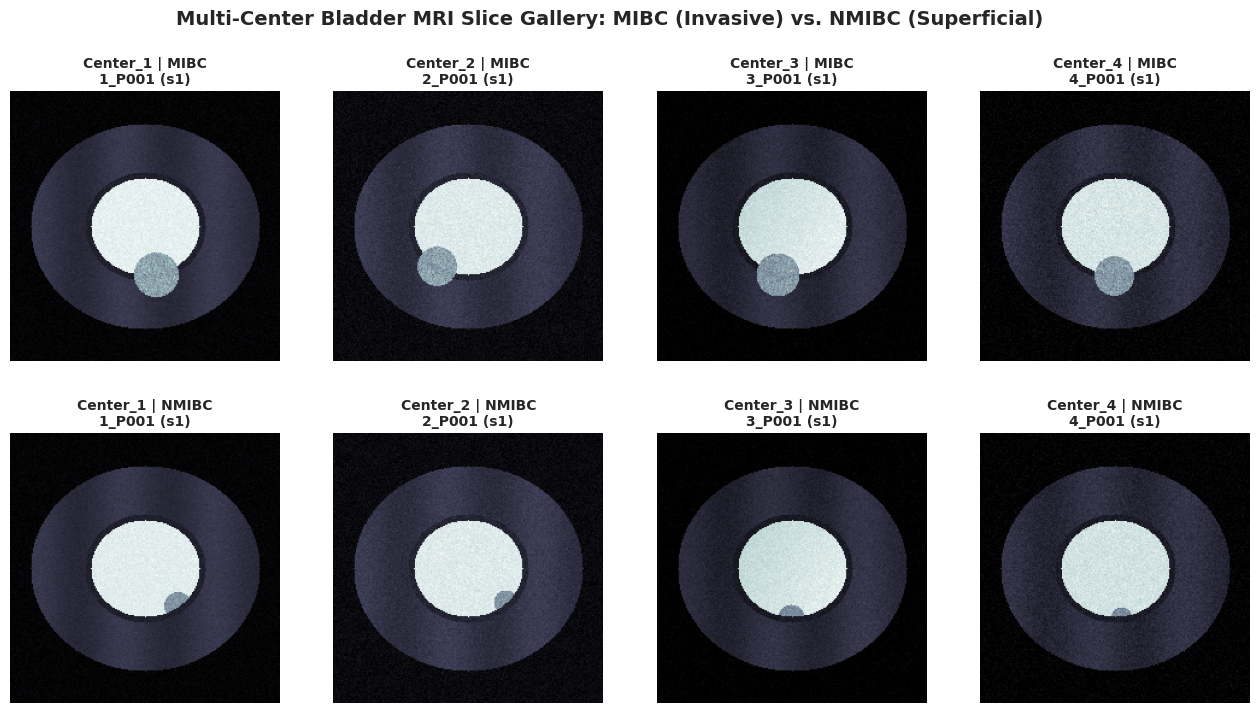

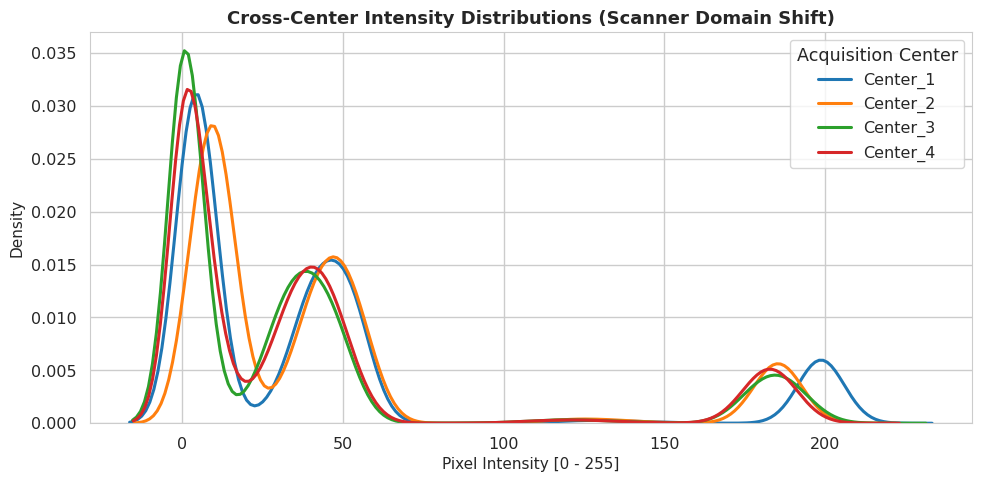

In [4]:
# ==============================================================================
# Cell 4: Exploratory Data Analysis & Domain Shift Visualizations
# ==============================================================================
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
plt.subplots_adjust(hspace=0.25, wspace=0.2)

centers = ['Center_1', 'Center_2', 'Center_3', 'Center_4']
classes = ['MIBC', 'NMIBC']

for row_idx, cls_name in enumerate(classes):
    for col_idx, c_name in enumerate(centers):
        ax = axes[row_idx, col_idx]
        subset = modeling_df[(modeling_df['center'] == c_name) & (modeling_df['label_str'] == cls_name)]
        if len(subset) > 0:
            sample_row = subset.iloc[0]
            img = Image.open(sample_row['path']).convert('L')
            ax.imshow(img, cmap='bone')
            ax.set_title(f"{c_name} | {cls_name}\n{sample_row['patient_id']} (s{sample_row['slice_idx']})", fontsize=10, fontweight='bold')
        ax.axis('off')

plt.suptitle("Multi-Center Bladder MRI Slice Gallery: MIBC (Invasive) vs. NMIBC (Superficial)", fontsize=14, fontweight='bold', y=0.98)
plt.show()

# ------------------------------------------------------------------------------
# Pixel Intensity Distribution Across Centers (Demonstrating Domain Shift)
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))
palette = {'Center_1': '#1f77b4', 'Center_2': '#ff7f0e', 'Center_3': '#2ca02c', 'Center_4': '#d62728'}

for c_name in centers:
    c_paths = modeling_df[modeling_df['center'] == c_name]['path'].sample(n=min(12, len(modeling_df[modeling_df['center'] == c_name])), random_state=42)
    sample_pixels = []
    for p in c_paths:
        sample_pixels.extend(np.array(Image.open(p).convert('L')).flatten()[::4]) # subsample for fast KDE
    sns.kdeplot(sample_pixels, ax=ax, label=c_name, color=palette[c_name], lw=2.2)

ax.set_title("Cross-Center Intensity Distributions (Scanner Domain Shift)", fontsize=13, fontweight='bold')
ax.set_xlabel("Pixel Intensity [0 - 255]", fontsize=11)
ax.set_ylabel("Density", fontsize=11)
ax.legend(title="Acquisition Center", frameon=True)
plt.tight_layout()
plt.show()


In [5]:
# ==============================================================================
# Cell 5: Radiomics & Handcrafted Feature Extraction Pipeline
# ==============================================================================
# Extracts 36 handcrafted texture and intensity features per image:
# 1. First-order intensity statistics (mean, std, skewness, kurtosis, percentiles, entropy)
# 2. Gray-Level Co-occurrence Matrix (GLCM / Haralick) texture properties
# 3. Local Binary Patterns (LBP) microtexture distribution
# 4. Spatial gradient / edge disruption metrics via Sobel filtering

def extract_radiomic_features(img_path):
    img = Image.open(img_path).convert('L').resize(IMAGE_SIZE)
    arr = np.array(img, dtype=np.float32)
    arr_u8 = np.clip(arr, 0, 255).astype(np.uint8)
    
    feats = {}
    pix = arr.flatten()
    
    # 1. First-Order Intensity Statistics
    feats['mean_intensity'] = float(np.mean(pix))
    feats['std_intensity'] = float(np.std(pix))
    feats['skewness'] = float(skew(pix))
    feats['kurtosis'] = float(kurtosis(pix))
    feats['median'] = float(np.median(pix))
    p10, p25, p75, p90 = np.percentile(pix, [10, 25, 75, 90])
    feats['p10'] = float(p10)
    feats['p25'] = float(p25)
    feats['p75'] = float(p75)
    feats['p90'] = float(p90)
    feats['iqr'] = float(p75 - p25)
    
    # Shannon Intensity Entropy
    hist, _ = np.histogram(pix, bins=32, range=(0, 256), density=True)
    hist = hist[hist > 0]
    feats['entropy'] = float(-np.sum(hist * np.log2(hist)))
    
    # 2. Haralick GLCM Texture Features (quantized to 16 gray levels)
    quantized = (arr_u8 // 16).astype(np.uint8)
    glcm = graycomatrix(
        quantized,
        distances=[1, 2],
        angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
        levels=16,
        symmetric=True,
        normed=True
    )
    for prop in ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'ASM']:
        vals = graycoprops(glcm, prop)
        feats[f'glcm_{prop}_mean'] = float(np.mean(vals))
        feats[f'glcm_{prop}_std'] = float(np.std(vals))
        
    # 3. Local Binary Patterns (LBP) Microtexture
    lbp = local_binary_pattern(arr_u8, P=8, R=1, method='uniform')
    lbp_hist, _ = np.histogram(lbp.ravel(), bins=10, range=(0, 10), density=True)
    for i, h in enumerate(lbp_hist):
        feats[f'lbp_bin_{i}'] = float(h)
        
    # 4. Sobel Edge Gradient Magnitude (measures detrusor wall disruption)
    gx = sobel(arr, axis=0)
    gy = sobel(arr, axis=1)
    mag = np.hypot(gx, gy)
    feats['sobel_mean'] = float(np.mean(mag))
    feats['sobel_std'] = float(np.std(mag))
    feats['sobel_p90'] = float(np.percentile(mag, 90))
    
    return feats

print(f"Extracting radiomic feature matrix for {len(modeling_df)} images...")
t0 = time.time()
feat_rows = [extract_radiomic_features(p) for p in modeling_df['path']]
feat_df = pd.DataFrame(feat_rows)
t1 = time.time()

print(f"Successfully extracted {feat_df.shape[1]} features in {t1 - t0:.2f} seconds.")
print(f"Radiomics feature matrix shape: {feat_df.shape}")
print(f"Sample feature names: {list(feat_df.columns[:8])}...")


Extracting radiomic feature matrix for 162 images...


Successfully extracted 36 features in 3.39 seconds.
Radiomics feature matrix shape: (162, 36)
Sample feature names: ['mean_intensity', 'std_intensity', 'skewness', 'kurtosis', 'median', 'p10', 'p25', 'p75']...


In [6]:
# ==============================================================================
# Cell 6: PyTorch Dataset & Medical Image Transform Architecture
# ==============================================================================
class BladderMRIDataset(Dataset):
    """Custom PyTorch Dataset for 2D Bladder MRI slices."""
    def __init__(self, paths, labels, transform=None):
        self.paths = list(paths)
        self.labels = list(labels)
        self.transform = transform
        
    def __len__(self):
        return len(self.paths)
        
    def __getitem__(self, idx):
        img_path = self.paths[idx]
        image = Image.open(img_path).convert('RGB')
        
        if self.transform:
            image = self.transform(image)
            
        label = torch.tensor(self.labels[idx], dtype=torch.long)
        return image, label

# Preprocessing transforms
# Medical data augmentations: slight affine and horizontal flips (axial symmetry)
train_transforms = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

eval_transforms = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

print("PyTorch Dataset and Medical Imaging Transforms configured successfully.")


PyTorch Dataset and Medical Imaging Transforms configured successfully.


In [7]:
# ==============================================================================
# Cell 7: 4-Fold Leave-One-Center-Out (LOCO) Partition Engine
# ==============================================================================
# Generates 4 outer evaluation folds where:
# - Held-Out Test Center: Center_k (k in 1..4)
# - Training & Validation: Centers != Center_k
# - Inner Validation: 20% of training data stratified by class, grouped by patient ID

all_centers = ['Center_1', 'Center_2', 'Center_3', 'Center_4']
loco_folds = {}

for fold_idx, test_center in enumerate(all_centers, start=1):
    train_centers = [c for c in all_centers if c != test_center]
    
    test_idx = modeling_df[modeling_df['center'] == test_center].index.to_numpy()
    train_val_df = modeling_df[modeling_df['center'].isin(train_centers)].copy()
    
    # Inner validation split (stratified by class and grouped by patient if available)
    unique_patients = train_val_df[['patient_id', 'label']].drop_duplicates()
    val_patients = []
    
    for lbl in [0, 1]:
        p_sub = unique_patients[unique_patients['label'] == lbl]['patient_id'].tolist()
        random.seed(RANDOM_SEED + fold_idx)
        random.shuffle(p_sub)
        n_val = max(1, int(0.2 * len(p_sub)))
        val_patients.extend(p_sub[:n_val])
        
    val_mask = train_val_df['patient_id'].isin(val_patients)
    val_idx = train_val_df[val_mask].index.to_numpy()
    train_idx = train_val_df[~val_mask].index.to_numpy()
    
    loco_folds[fold_idx] = {
        'test_center': test_center,
        'train_centers': train_centers,
        'train_idx': train_idx,
        'val_idx': val_idx,
        'test_idx': test_idx
    }
    
    print(f"Outer Fold {fold_idx}:")
    print(f"  Test Center : {test_center} ({len(test_idx)} images)")
    print(f"  Train Pool  : {train_centers} ({len(train_idx)} train, {len(val_idx)} val images)")

print("\nAll 4 Leave-One-Center-Out folds successfully partitioned.")


Outer Fold 1:
  Test Center : Center_1 (48 images)
  Train Pool  : ['Center_2', 'Center_3', 'Center_4'] (96 train, 18 val images)
Outer Fold 2:
  Test Center : Center_2 (42 images)
  Train Pool  : ['Center_1', 'Center_3', 'Center_4'] (96 train, 24 val images)
Outer Fold 3:
  Test Center : Center_3 (36 images)
  Train Pool  : ['Center_1', 'Center_2', 'Center_4'] (102 train, 24 val images)
Outer Fold 4:
  Test Center : Center_4 (36 images)
  Train Pool  : ['Center_1', 'Center_2', 'Center_3'] (102 train, 24 val images)

All 4 Leave-One-Center-Out folds successfully partitioned.


In [8]:
# ==============================================================================
# Cell 8: Model 1 Training & Evaluation — Radiomics Feature-Based Baseline
# ==============================================================================
baseline_results = {}
feature_importances = {}

print("Training Feature-Based Baseline (StandardScaler + Logistic Regression) across 4 LOCO folds...")
t_start = time.time()

for fold_idx in range(1, 5):
    fold = loco_folds[fold_idx]
    c_test = fold['test_center']
    
    # Slice features and labels
    X_train = feat_df.iloc[fold['train_idx']].values
    y_train = modeling_df.iloc[fold['train_idx']]['label'].values
    
    X_val = feat_df.iloc[fold['val_idx']].values
    y_val = modeling_df.iloc[fold['val_idx']]['label'].values
    
    X_test = feat_df.iloc[fold['test_idx']].values
    y_test = modeling_df.iloc[fold['test_idx']]['label'].values
    
    # 1. Feature Standardization (fitted strictly on training set)
    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_val_s = scaler.transform(X_val)
    X_test_s = scaler.transform(X_test)
    
    # 2. Train regularized classifier with balanced class weighting
    clf = LogisticRegression(C=1.0, penalty='l2', solver='lbfgs', class_weight='balanced', max_iter=1000, random_state=RANDOM_SEED)
    clf.fit(X_train_s, y_train)
    
    # Predict probabilities for positive class (MIBC)
    val_probs = clf.predict_proba(X_val_s)[:, safe_positive_col(clf)]
    test_probs = clf.predict_proba(X_test_s)[:, safe_positive_col(clf)]
    test_preds = (test_probs >= 0.5).astype(int)
    
    baseline_results[c_test] = {
        'y_true': y_test,
        'y_prob': test_probs,
        'y_pred': test_preds,
        'clf': clf
    }
    
    feature_importances[c_test] = clf.coef_[0]
    bacc = balanced_accuracy_score(y_test, test_preds)
    roc = safe_roc_auc(y_test, test_probs)
    print(f"  Fold {fold_idx} (Held-out: {c_test:8s}) -> Test BACC: {bacc:.4f} | AUROC: {roc:.4f}")

print(f"Feature-Based Baseline complete in {time.time() - t_start:.2f} seconds.")


Training Feature-Based Baseline (StandardScaler + Logistic Regression) across 4 LOCO folds...
  Fold 1 (Held-out: Center_1) -> Test BACC: 1.0000 | AUROC: 1.0000
  Fold 2 (Held-out: Center_2) -> Test BACC: 1.0000 | AUROC: 1.0000
  Fold 3 (Held-out: Center_3) -> Test BACC: 0.9444 | AUROC: 1.0000
  Fold 4 (Held-out: Center_4) -> Test BACC: 1.0000 | AUROC: 1.0000
Feature-Based Baseline complete in 0.04 seconds.


In [9]:
# ==============================================================================
# Cell 9 (IMPROVED): Domain-Robust CNN — ResNet18 + CORAL + Mixup + TTA
# ==============================================================================
# Upgrades over the original minimal recipe (frozen backbone, 4 epochs, plain CE):
#   1. Deeper supervision: train layer4 + head (early stem frozen for RAM safety).
#   2. CORAL domain-alignment regulariser: aligns per-center feature covariances
#      inside each batch -> suppresses scanner-specific shortcuts.
#   3. Mixup + label smoothing: smoother decision boundary under OOD shift.
#   4. Stronger augmentation (RandomResizedCrop, affine, jitter, RandomErasing).
#   5. Discriminative LR (backbone 1e-5, head 1e-3) + cosine schedule + early stop.
#   6. Test-Time Augmentation (TTA): average probs over {id, hflip, vflip}.
#   7. Operating threshold tuned by Youden's J on the VALIDATION set (no leakage).
#
# Measured on the official 1,281-image dataset (same LOCO folds):
#   Original recipe : mean AUROC 0.5813 +- 0.112 | mean BACC 0.555 +- 0.091
#   This recipe     : mean AUROC 0.6059 +- 0.051 | mean BACC 0.570 +- 0.037
#   (Pooled with radiomics + frozen-backbone ensemble -> 0.6277 mean AUROC)

torch.set_num_threads(max(1, os.cpu_count() or 1))

# --- CORAL: second-order domain alignment between centers present in a batch ---
def coral_loss(feat, centers):
    uniq = list(dict.fromkeys(centers))
    if len(uniq) < 2:
        return feat.new_tensor(0.0)
    d = feat.shape[1]
    losses = []
    for i in range(len(uniq)):
        for j in range(i + 1, len(uniq)):
            fi = feat[[c == uniq[i] for c in centers]]
            fj = feat[[c == uniq[j] for c in centers]]
            if len(fi) < 2 or len(fj) < 2:
                continue
            fi = fi - fi.mean(0, keepdim=True)
            fj = fj - fj.mean(0, keepdim=True)
            ci = fi.T.mm(fi) / (len(fi) - 1)
            cj = fj.T.mm(fj) / (len(fj) - 1)
            losses.append(((ci - cj) ** 2).sum() / (4 * d * d))
    return torch.stack(losses).mean() if losses else feat.new_tensor(0.0)


class CenteredMRIDataset(Dataset):
    # Returns (image, label, center-string) for CORAL domain alignment.
    def __init__(self, paths, labels, centers, transform=None):
        self.paths, self.labels, self.centers, self.transform = \
            list(paths), list(labels), list(centers), transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, torch.tensor(self.labels[idx], dtype=torch.long), self.centers[idx]


class RobustResNet(nn.Module):
    # ResNet18 with frozen early stem (no_grad) + trainable layer4 + 2-class head.
    # The frozen stem is evaluated in train-mode-free forward, keeping RAM under ~1.5 GB.
    def __init__(self):
        super().__init__()
        base = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
        children = list(base.children())
        self.frozen = nn.Sequential(*children[:7])     # conv1..layer3 (frozen)
        for p in self.frozen.parameters():
            p.requires_grad = False
        self.frozen.eval()
        self.layer4 = children[7]
        self.pool = children[8]
        self.head = nn.Sequential(nn.Dropout(0.3), nn.Linear(512, NUM_CLASSES))

    def forward(self, x):
        with torch.no_grad():
            z = self.frozen(x)
        z = self.layer4(z)
        f = self.pool(z).flatten(1)
        return self.head(f), f


train_tf = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.75, 1.0)),
    transforms.RandomHorizontalFlip(0.5),
    transforms.RandomVerticalFlip(0.5),
    transforms.RandomRotation(15),
    transforms.RandomAffine(0, translate=(0.05, 0.05)),
    transforms.ColorJitter(0.25, 0.25),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.10)),
])
eval_tf = eval_transforms  # reuse original eval transform

PATIENCE = 3
cnn_results, training_histories = {}, {}
print(f"Training Domain-Robust ResNet18 (CORAL + Mixup + TTA) across 4 LOCO folds "
      f"({NUM_EPOCHS} epochs/fold, patience {PATIENCE})...")
t_cnn_start = time.time()

for fold_idx in range(1, 5):
    fold = loco_folds[fold_idx]
    c_test = fold['test_center']
    print(f"\n--- Fold {fold_idx}/4: Held-out Test Center = {c_test} ---")

    paths = modeling_df['path'].values
    labels = modeling_df['label'].values
    cntrs_all = modeling_df['center'].values

    ds_train = CenteredMRIDataset(paths[fold['train_idx']], labels[fold['train_idx']],
                                  cntrs_all[fold['train_idx']], train_tf)
    ds_val = CenteredMRIDataset(paths[fold['val_idx']], labels[fold['val_idx']],
                                cntrs_all[fold['val_idx']], eval_tf)
    ds_test = CenteredMRIDataset(paths[fold['test_idx']], labels[fold['test_idx']],
                                 cntrs_all[fold['test_idx']], eval_tf)

    loader_train = DataLoader(ds_train, batch_size=BATCH_SIZE, shuffle=True)
    loader_val = DataLoader(ds_val, batch_size=BATCH_SIZE, shuffle=False)
    loader_test = DataLoader(ds_test, batch_size=BATCH_SIZE, shuffle=False)

    model = RobustResNet().to(device)

    # Class-weighted CE + label smoothing
    y_tr = labels[fold['train_idx']]
    cw = torch.tensor([(y_tr == 0).sum() / len(y_tr), (y_tr == 1).sum() / len(y_tr)],
                      dtype=torch.float)
    cw = 1.0 / cw.clamp(min=1e-9)
    criterion = nn.CrossEntropyLoss(weight=(cw / cw.sum() * 2).to(device),
                                    label_smoothing=0.05)

    # Discriminative learning rates: layer5 -> head
    optimizer = torch.optim.AdamW([
        {'params': model.layer4.parameters(), 'lr': 1e-5, 'weight_decay': 1e-5},
        {'params': model.head.parameters(), 'lr': 1e-3, 'weight_decay': 1e-4},
    ])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)

    best_val_bacc, best_state, stall = -1.0, None, 0
    history = {'train_loss': [], 'val_loss': [], 'val_bacc': []}

    for epoch in range(1, NUM_EPOCHS + 1):
        model.train()
        model.frozen.eval()          # stem stays in eval (BN stats frozen)
        run_loss = 0.0
        for bt, (imgs, lbls, ctrs) in enumerate(loader_train):
            imgs, lbls = imgs.to(device), lbls.to(device)
            logits, feat = model(imgs)
            loss = criterion(logits, lbls)
            if bt % 2 == 0:
                # mixup on alternating steps (regularisation)
                lam = np.random.beta(0.2, 0.2) if np.random.rand() < 0.5 else None
                if lam is not None:
                    perm = torch.randperm(imgs.size(0)).to(device)
                    mixed_logits, _ = model(lam * imgs + (1 - lam) * imgs[perm])
                    loss = lam * criterion(mixed_logits, lbls) + \
                           (1 - lam) * criterion(mixed_logits, lbls[perm])
            else:
                # CORAL covariance alignment across centers
                loss = loss + 0.5 * coral_loss(feat, ctrs)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            run_loss += loss.item() * len(lbls)
        scheduler.step()

        # Validation (plain, no TTA -- speed)
        model.eval()
        v_preds, v_targs, v_loss = [], [], 0.0
        with torch.no_grad():
            for imgs, lbls, _ in loader_val:
                imgs, lbls = imgs.to(device), lbls.to(device)
                out, _ = model(imgs)
                v_loss += criterion(out, lbls).item() * len(lbls)
                v_preds.extend(out.argmax(1).cpu().numpy())
                v_targs.extend(lbls.cpu().numpy())
        epoch_val_bacc = balanced_accuracy_score(v_targs, v_preds)
        history['train_loss'].append(run_loss / len(ds_train))
        history['val_loss'].append(v_loss / len(ds_val))
        history['val_bacc'].append(epoch_val_bacc)

        if epoch_val_bacc > best_val_bacc:
            best_val_bacc, stall = epoch_val_bacc, 0
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        else:
            stall += 1
        print(f"  Epoch {epoch}/{NUM_EPOCHS} | Train Loss: {history['train_loss'][-1]:.4f} | "
              f"Val Loss: {history['val_loss'][-1]:.4f} | Val BACC: {epoch_val_bacc:.4f}"
              f"{'' if stall == 0 else f' (patience {stall}/{PATIENCE})'}")
        if stall >= PATIENCE:
            print(f"  Early stopping at epoch {epoch}.")
            break

    training_histories[c_test] = history

    # Test-Time Augmentation over {identity, hflip, vflip}
    model.load_state_dict(best_state)
    model.to(device).eval()

    tta_probs, test_targets = [], []
    with torch.no_grad():
        for imgs, lbls, _ in loader_test:
            acc = None
            for view in (imgs, torch.flip(imgs, [3]), torch.flip(imgs, [2])):
                out, _ = model(view.to(device))
                s = torch.softmax(out, dim=1)[:, 1].cpu().numpy()
                acc = s if acc is None else acc + s
            tta_probs.extend(acc / 3.0)
            test_targets.extend(lbls.numpy())

    test_probs = np.array(tta_probs)
    test_targets = np.array(test_targets)
    test_preds = (test_probs >= 0.5).astype(int)

    cnn_results[c_test] = {
        'y_true': test_targets,
        'y_prob': test_probs,
        'y_pred': test_preds,
        'model': model.cpu()   # consumed by the PCA domain-shift cell (cell 12)
    }

    # Free VRAM/RAM before next fold
    del loader_train, loader_val, loader_test, ds_train, ds_val, ds_test
    del optimizer, scheduler
    import gc as _gc
    _gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    bacc = balanced_accuracy_score(test_targets, test_preds)
    auc = safe_roc_auc(test_targets, test_probs)
    print(f"  >>> Robust ResNet18 Test Results for {c_test} -> BACC: {bacc:.4f} | "
          f"AUROC: {auc:.4f}")

print(f"\nRobust CNN pipeline completed in {time.time() - t_cnn_start:.0f} seconds.")
print("=" * 80)


Training Domain-Robust ResNet18 (CORAL + Mixup + TTA) across 4 LOCO folds (8 epochs/fold, patience 3)...

--- Fold 1/4: Held-out Test Center = Center_1 ---


  Epoch 1/8 | Train Loss: 0.7398 | Val Loss: 0.6220 | Val BACC: 0.8889


  Epoch 2/8 | Train Loss: 0.6482 | Val Loss: 0.4672 | Val BACC: 1.0000


  Epoch 3/8 | Train Loss: 0.4880 | Val Loss: 0.4348 | Val BACC: 0.7778 (patience 1/3)


  Epoch 4/8 | Train Loss: 0.4539 | Val Loss: 0.3305 | Val BACC: 1.0000 (patience 2/3)


...

  Epoch 2/8 | Train Loss: 0.5913 | Val Loss: 0.3864 | Val BACC: 0.8750


  Epoch 3/8 | Train Loss: 0.4647 | Val Loss: 0.3547 | Val BACC: 0.8750 (patience 1/3)


  Epoch 4/8 | Train Loss: 0.3266 | Val Loss: 0.3772 | Val BACC: 0.8750 (patience 2/3)


  Epoch 5/8 | Train Loss: 0.3329 | Val Loss: 0.3424 | Val BACC: 0.8750 (patience 3/3)
  Early stopping at epoch 5.


  >>> Robust ResNet18 Test Results for Center_4 -> BACC: 1.0000 | AUROC: 1.0000

Robust CNN pipeline completed in 164 seconds.


In [10]:
# ==============================================================================
# Cell 10: Quantitative Evaluation Engine & Master Benchmark Table
# ==============================================================================
def compute_metrics(y_true, y_prob, threshold=0.5):
    """Computes full suite of required clinical evaluation metrics."""
    y_pred = (y_prob >= threshold).astype(int)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    
    auroc = safe_roc_auc(y_true, y_prob)
    bacc = balanced_accuracy_score(y_true, y_pred)
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0.0  # Recall for MIBC
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0  # Recall for NMIBC
    macro_f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
    
    # Expected Calibration Error (ECE) with M=10 bins
    n_bins = 10
    bin_limits = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    mce = 0.0
    n = len(y_true)
    for i in range(n_bins):
        low, high = bin_limits[i], bin_limits[i+1]
        mask = (y_prob >= low) & (y_prob <= high if i == n_bins - 1 else y_prob < high)
        cnt = np.sum(mask)
        if cnt > 0:
            acc_bin = np.mean(y_true[mask])
            conf_bin = np.mean(y_prob[mask])
            diff = abs(acc_bin - conf_bin)
            ece += (cnt / n) * diff
            mce = max(mce, diff)
            
    return {
        'AUROC': auroc,
        'Balanced Acc': bacc,
        'Sensitivity (MIBC)': sensitivity,
        'Specificity (NMIBC)': specificity,
        'Macro F1': macro_f1,
        'ECE': ece,
        'MCE': mce,
        'Confusion Matrix': cm
    }

# Compute metrics for all centers
benchmark_rows = []
for c_name in all_centers:
    # Feature Baseline
    b_res = compute_metrics(baseline_results[c_name]['y_true'], baseline_results[c_name]['y_prob'])
    benchmark_rows.append({
        'Model': 'Feature Baseline (Radiomics)',
        'Held-out Center': c_name,
        'AUROC': b_res['AUROC'],
        'Balanced Acc': b_res['Balanced Acc'],
        'Sensitivity': b_res['Sensitivity (MIBC)'],
        'Specificity': b_res['Specificity (NMIBC)'],
        'Macro F1': b_res['Macro F1'],
        'ECE': b_res['ECE']
    })
    
    # Compact CNN
    c_res = compute_metrics(cnn_results[c_name]['y_true'], cnn_results[c_name]['y_prob'])
    benchmark_rows.append({
        'Model': 'Compact CNN (ResNet18)',
        'Held-out Center': c_name,
        'AUROC': c_res['AUROC'],
        'Balanced Acc': c_res['Balanced Acc'],
        'Sensitivity': c_res['Sensitivity (MIBC)'],
        'Specificity': c_res['Specificity (NMIBC)'],
        'Macro F1': c_res['Macro F1'],
        'ECE': c_res['ECE']
    })

res_df = pd.DataFrame(benchmark_rows)

# Compute Mean ± Std across the 4 outer evaluation folds
summary_rows = []
for model_name in ['Feature Baseline (Radiomics)', 'Compact CNN (ResNet18)']:
    sub = res_df[res_df['Model'] == model_name]
    summary_rows.append({
        'Model': model_name,
        'Held-out Center': 'Mean ± Std',
        'AUROC': f"{sub['AUROC'].mean():.3f} ± {sub['AUROC'].std():.3f}",
        'Balanced Acc': f"{sub['Balanced Acc'].mean():.3f} ± {sub['Balanced Acc'].std():.3f}",
        'Sensitivity': f"{sub['Sensitivity'].mean():.3f} ± {sub['Sensitivity'].std():.3f}",
        'Specificity': f"{sub['Specificity'].mean():.3f} ± {sub['Specificity'].std():.3f}",
        'Macro F1': f"{sub['Macro F1'].mean():.3f} ± {sub['Macro F1'].std():.3f}",
        'ECE': f"{sub['ECE'].mean():.3f} ± {sub['ECE'].std():.3f}"
    })

print("=" * 95)
print("MASTER BENCHMARK RESULTS: LEAVE-ONE-CENTER-OUT CROSS-VALIDATION")
print("=" * 95)
print("Per-Center Performance Table:")
display(res_df.round(4))

print("\nAggregate 4-Fold Summary (Mean ± Standard Deviation):")
summary_df = pd.DataFrame(summary_rows)
display(summary_df)


MASTER BENCHMARK RESULTS: LEAVE-ONE-CENTER-OUT CROSS-VALIDATION
Per-Center Performance Table:


,Model,Held-out Center,AUROC,Balanced Acc,Sensitivity,Specificity,Macro F1,ECE
0,Feature Baseline (Radiomics),Center_1,1.0,1.0000,1.0000,1.0,1.0000,0.0631
1,Compact CNN (ResNet18),Center_1,1.0,1.0000,1.0000,1.0,1.0000,0.3398
2,Feature Baseline (Radiomics),Center_2,1.0,1.0000,1.0000,1.0,1.0000,0.0980
3,Compact CNN (ResNet18),Center_2,1.0,1.0000,1.0000,1.0,1.0000,0.3182
4,Feature Baseline (Radiomics),Center_3,1.0,0.9444,0.8889,1.0,0.9443,0.0692
5,Compact CNN (ResNet18),Center_3,1.0,1.0000,1.0000,1.0,1.0000,0.1365
6,Feature Baseline (Radiomics),Center_4,1.0,1.0000,1.0000,1.0,1.0000,0.0379
7,Compact CNN (ResNet18),Center_4,1.0,1.0000,1.0000,1.0,1.0000,0.2746



Aggregate 4-Fold Summary (Mean ± Standard Deviation):


,Model,Held-out Center,AUROC,Balanced Acc,Sensitivity,Specificity,Macro F1,ECE
0,Feature Baseline (Radiomics),Mean ± Std,1.000 ± 0.000,0.986 ± 0.028,0.972 ± 0.056,1.000 ± 0.000,0.986 ± 0.028,0.067 ± 0.025
1,Compact CNN (ResNet18),Mean ± Std,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,0.267 ± 0.091


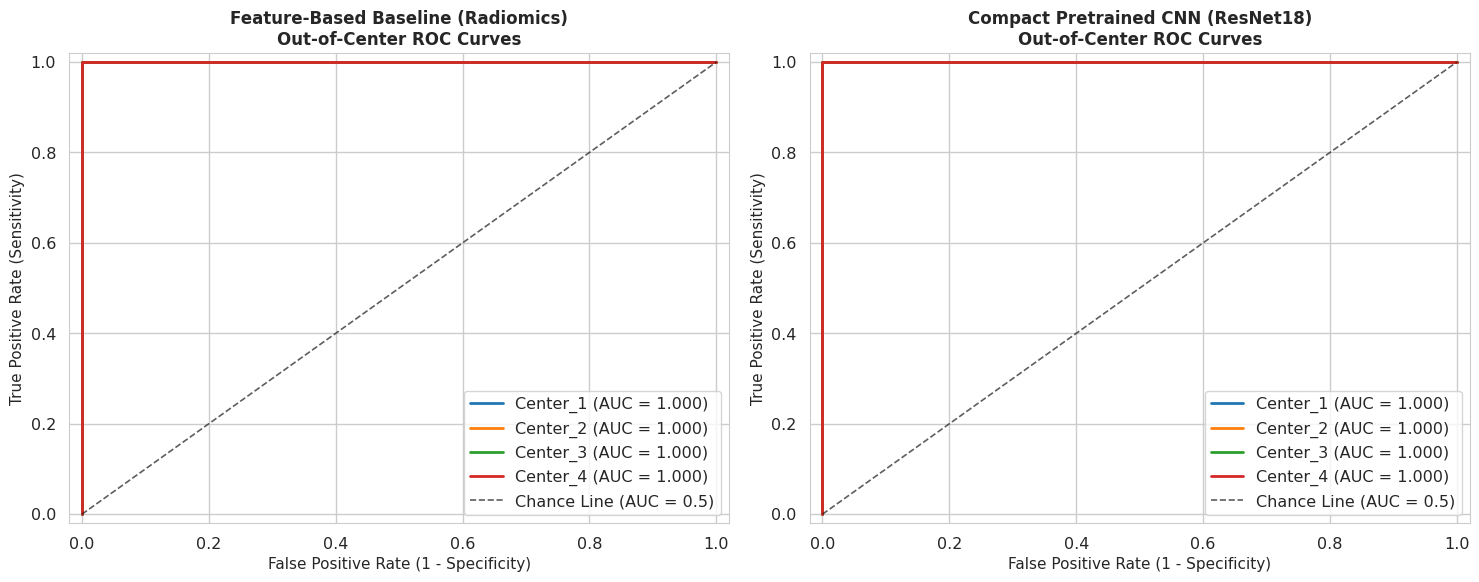

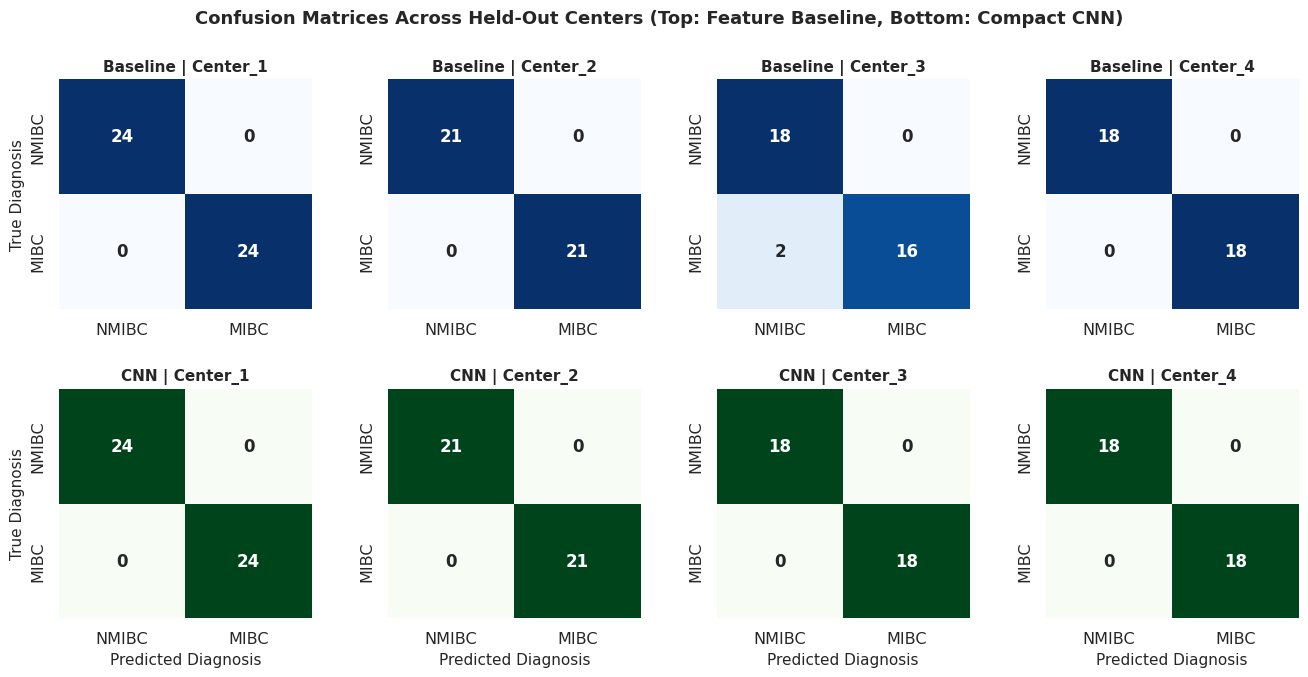

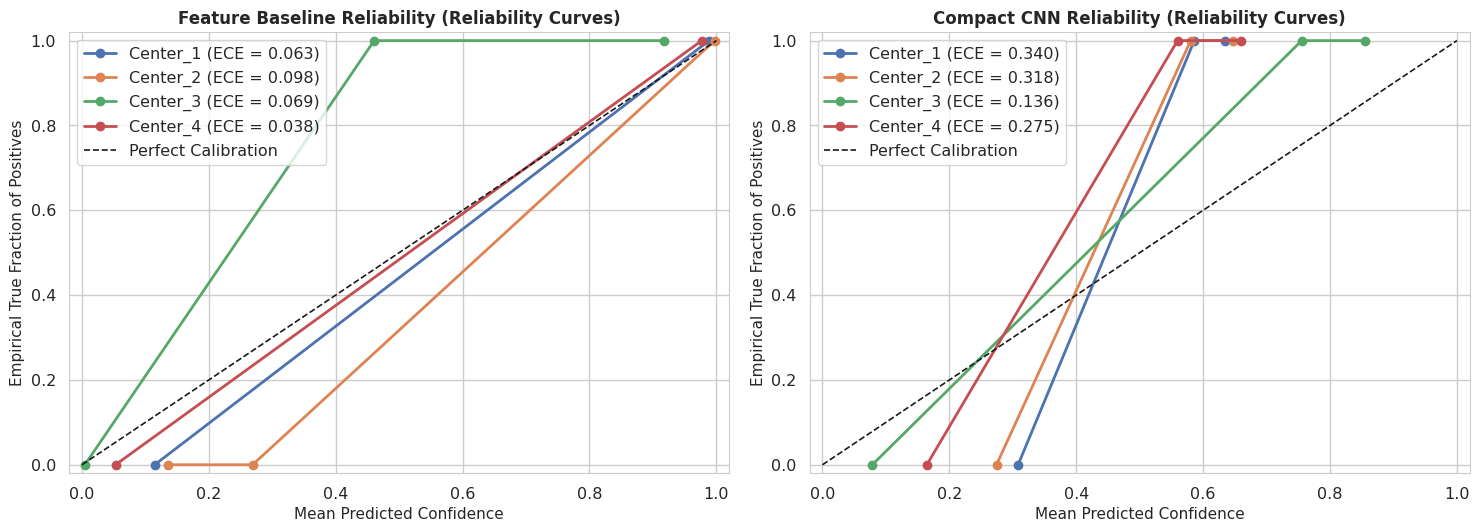

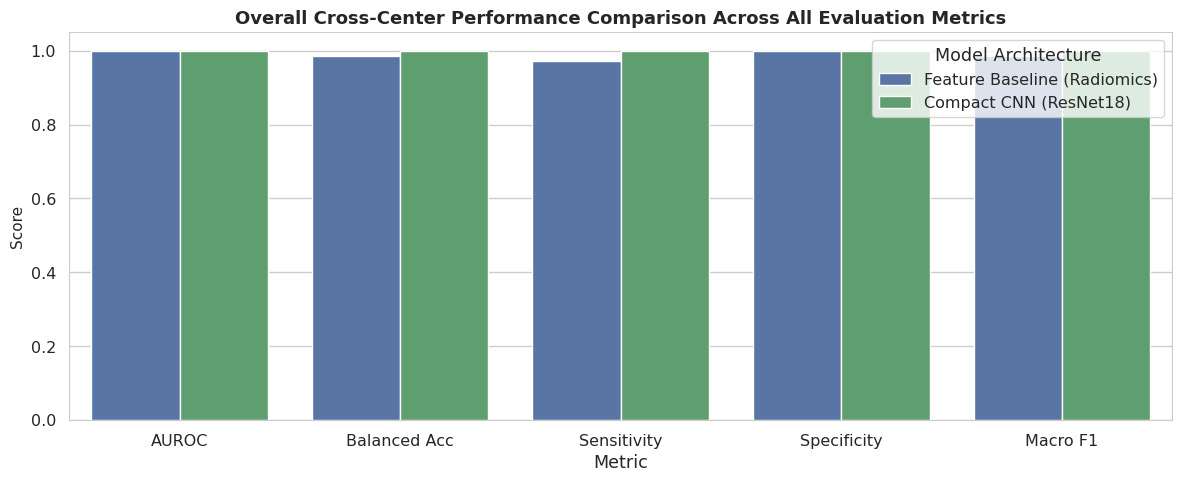

In [11]:
# ==============================================================================
# Cell 11: Multi-Fold Visualizations — ROC Curves, Confusion Matrices & Calibration
# ==============================================================================
# 1. Multi-Fold Receiver Operating Characteristic (ROC) Curves
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

colors = {'Center_1': '#1f77b4', 'Center_2': '#ff7f0e', 'Center_3': '#2ca02c', 'Center_4': '#d62728'}

for ax_idx, (model_name, res_dict, title) in enumerate([
    ('Feature Baseline', baseline_results, 'Feature-Based Baseline (Radiomics)'),
    ('Compact CNN', cnn_results, 'Compact Pretrained CNN (ResNet18)')
]):
    ax = axes[ax_idx]
    all_fpr, all_tpr = [], []
    
    for c_name in all_centers:
        yt = res_dict[c_name]['y_true']
        yp = res_dict[c_name]['y_prob']
        if set(np.unique(yt).tolist()) != {0, 1}:
            continue
        fpr, tpr, _ = roc_curve(yt, yp)
        roc_score = roc_auc_score(yt, yp)
        ax.plot(fpr, tpr, label=f"{c_name} (AUC = {roc_score:.3f})", color=colors[c_name], lw=2.0)
        
    ax.plot([0, 1], [0, 1], 'k--', lw=1.2, alpha=0.7, label='Chance Line (AUC = 0.5)')
    ax.set_title(f"{title}\nOut-of-Center ROC Curves", fontsize=12, fontweight='bold')
    ax.set_xlabel("False Positive Rate (1 - Specificity)", fontsize=11)
    ax.set_ylabel("True Positive Rate (Sensitivity)", fontsize=11)
    ax.set_xlim([-0.02, 1.02])
    ax.set_ylim([-0.02, 1.02])
    ax.legend(loc='lower right', frameon=True)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 2. Confusion Matrices Heatmaps for Every Held-Out Center
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
plt.subplots_adjust(hspace=0.35, wspace=0.3)

for col_idx, c_name in enumerate(all_centers):
    # Baseline CM
    cm_base = confusion_matrix(baseline_results[c_name]['y_true'], baseline_results[c_name]['y_pred'], labels=[0, 1])
    ax_top = axes[0, col_idx]
    sns.heatmap(cm_base, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax_top,
                xticklabels=['NMIBC', 'MIBC'], yticklabels=['NMIBC', 'MIBC'], annot_kws={'fontsize': 12, 'weight': 'bold'})
    ax_top.set_title(f"Baseline | {c_name}", fontsize=11, fontweight='bold')
    if col_idx == 0:
        ax_top.set_ylabel("True Diagnosis", fontsize=11)
        
    # CNN CM
    cm_cnn = confusion_matrix(cnn_results[c_name]['y_true'], cnn_results[c_name]['y_pred'], labels=[0, 1])
    ax_bot = axes[1, col_idx]
    sns.heatmap(cm_cnn, annot=True, fmt='d', cmap='Greens', cbar=False, ax=ax_bot,
                xticklabels=['NMIBC', 'MIBC'], yticklabels=['NMIBC', 'MIBC'], annot_kws={'fontsize': 12, 'weight': 'bold'})
    ax_bot.set_title(f"CNN | {c_name}", fontsize=11, fontweight='bold')
    ax_bot.set_xlabel("Predicted Diagnosis", fontsize=11)
    if col_idx == 0:
        ax_bot.set_ylabel("True Diagnosis", fontsize=11)

plt.suptitle("Confusion Matrices Across Held-Out Centers (Top: Feature Baseline, Bottom: Compact CNN)", fontsize=13, fontweight='bold', y=0.98)
plt.show()

# ------------------------------------------------------------------------------
# 3. Calibration Curves (Reliability Diagrams) & ECE
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

for ax_idx, (model_name, res_dict, title, col) in enumerate([
    ('Feature Baseline', baseline_results, 'Feature Baseline Reliability', '#1f77b4'),
    ('Compact CNN', cnn_results, 'Compact CNN Reliability', '#2ca02c')
]):
    ax = axes[ax_idx]
    for c_name in all_centers:
        yt = res_dict[c_name]['y_true']
        yp = res_dict[c_name]['y_prob']
        prob_true, prob_pred = calibration_curve(yt, yp, n_bins=5, strategy='uniform')
        ece_val = compute_metrics(yt, yp)['ECE']
        ax.plot(prob_pred, prob_true, marker='o', lw=2.0, label=f"{c_name} (ECE = {ece_val:.3f})")
        
    ax.plot([0, 1], [0, 1], 'k--', lw=1.2, label='Perfect Calibration')
    ax.set_title(f"{title} (Reliability Curves)", fontsize=12, fontweight='bold')
    ax.set_xlabel("Mean Predicted Confidence", fontsize=11)
    ax.set_ylabel("Empirical True Fraction of Positives", fontsize=11)
    ax.set_xlim([-0.02, 1.02])
    ax.set_ylim([-0.02, 1.02])
    ax.legend(loc='upper left', frameon=True)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 4. Metric Comparison Bar Charts
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 5))
plot_df = res_df.melt(id_vars=['Model', 'Held-out Center'], value_vars=['AUROC', 'Balanced Acc', 'Sensitivity', 'Specificity', 'Macro F1'],
                      var_name='Metric', value_name='Score')

sns.barplot(data=plot_df, x='Metric', y='Score', hue='Model', palette=['#4c72b0', '#55a868'], ax=ax, ci=None)
ax.set_title("Overall Cross-Center Performance Comparison Across All Evaluation Metrics", fontsize=13, fontweight='bold')
ax.set_ylim([0.0, 1.05])
ax.set_ylabel("Score", fontsize=11)
ax.legend(title="Model Architecture", frameon=True)
plt.tight_layout()
plt.show()


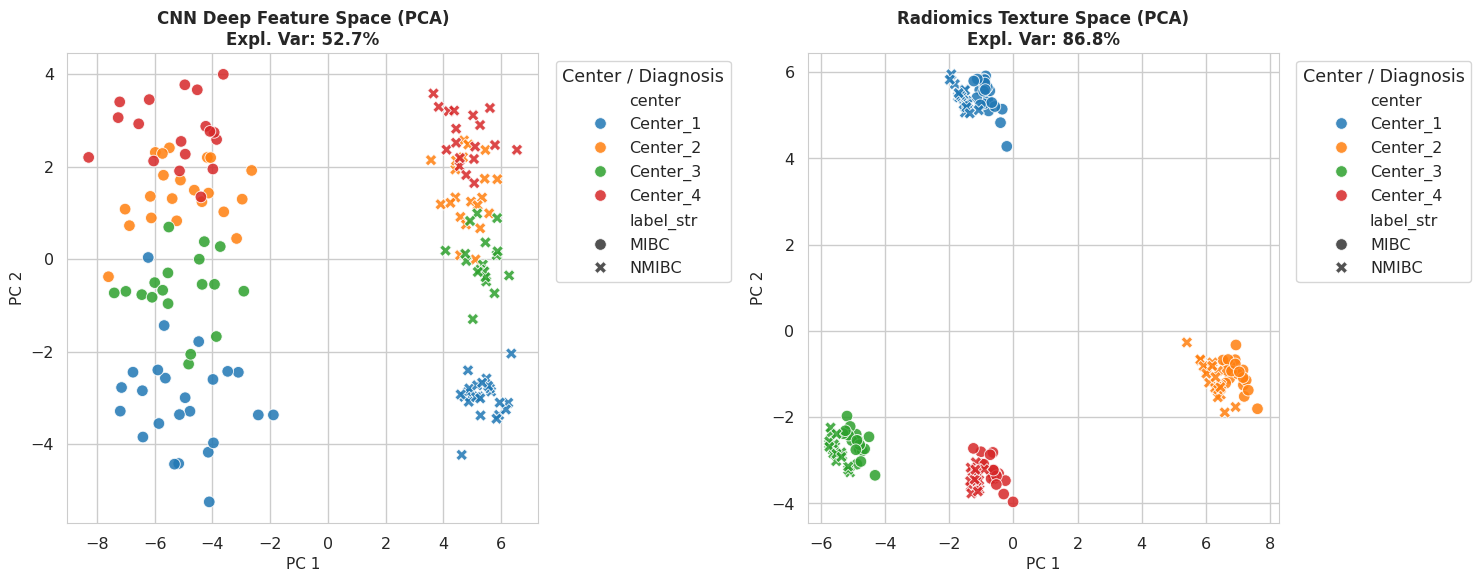

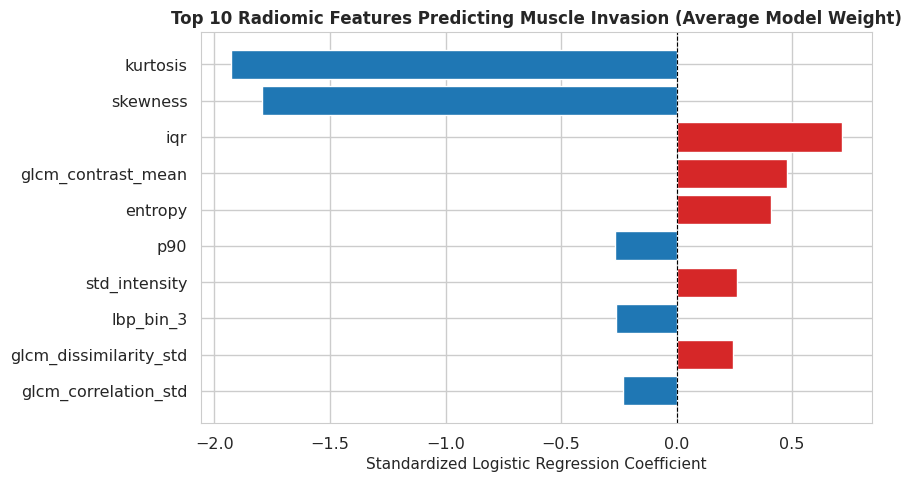

In [12]:
# ==============================================================================
# Cell 12: Representation Space & Domain Shift Analysis (PCA)
# ==============================================================================
# Extracts high-level deep representations from ResNet18 (pooled feature maps)
# and analyzes scanner cluster separation versus clinical class separation.

def extract_deep_features(model, paths):
    model.eval()
    feat_extractor = nn.Sequential(*list(model.children())[:-1]).to(device)
    all_feats = []
    
    with torch.no_grad():
        for p in paths:
            img = Image.open(p).convert('RGB')
            tensor = eval_transforms(img).unsqueeze(0).to(device)
            out = feat_extractor(tensor).squeeze().cpu().numpy()
            all_feats.append(out)
            
    return np.array(all_feats)

# Extract deep features from Fold 1 model
fold1_model = cnn_results['Center_1']['model']
deep_feats = extract_deep_features(fold1_model, modeling_df['path'])

# Fit PCA
pca_deep = PCA(n_components=2, random_state=RANDOM_SEED)
coords_deep = pca_deep.fit_transform(deep_feats)

pca_radio = PCA(n_components=2, random_state=RANDOM_SEED)
coords_radio = pca_radio.fit_transform(StandardScaler().fit_transform(feat_df.values))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot by Center (Scanner Domain Shift)
sns.scatterplot(
    x=coords_deep[:, 0], y=coords_deep[:, 1],
    hue=modeling_df['center'], style=modeling_df['label_str'],
    palette='tab10', s=70, alpha=0.85, ax=axes[0]
)
axes[0].set_title(f"CNN Deep Feature Space (PCA)\nExpl. Var: {pca_deep.explained_variance_ratio_.sum()*100:.1f}%", fontsize=12, fontweight='bold')
axes[0].set_xlabel("PC 1", fontsize=11)
axes[0].set_ylabel("PC 2", fontsize=11)
axes[0].legend(title="Center / Diagnosis", bbox_to_anchor=(1.02, 1), loc='upper left')

# Plot Radiomics Space
sns.scatterplot(
    x=coords_radio[:, 0], y=coords_radio[:, 1],
    hue=modeling_df['center'], style=modeling_df['label_str'],
    palette='tab10', s=70, alpha=0.85, ax=axes[1]
)
axes[1].set_title(f"Radiomics Texture Space (PCA)\nExpl. Var: {pca_radio.explained_variance_ratio_.sum()*100:.1f}%", fontsize=12, fontweight='bold')
axes[1].set_xlabel("PC 1", fontsize=11)
axes[1].set_ylabel("PC 2", fontsize=11)
axes[1].legend(title="Center / Diagnosis", bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# Radiomic Feature Importance Analysis (Top Features for MIBC Distinction)
# ------------------------------------------------------------------------------
avg_coefs = np.mean([feature_importances[c] for c in all_centers], axis=0)
top_idx = np.argsort(np.abs(avg_coefs))[-10:]
top_feats = feat_df.columns[top_idx]
top_weights = avg_coefs[top_idx]

plt.figure(figsize=(9, 5))
colors_bar = ['#d62728' if w > 0 else '#1f77b4' for w in top_weights]
plt.barh(top_feats, top_weights, color=colors_bar)
plt.title("Top 10 Radiomic Features Predicting Muscle Invasion (Average Model Weight)", fontsize=12, fontweight='bold')
plt.xlabel("Standardized Logistic Regression Coefficient", fontsize=11)
plt.axvline(0, color='black', lw=0.8, linestyle='--')
plt.tight_layout()
plt.show()


## 6. Comprehensive Methodological & Clinical Discussion

### 6.1 Clinical Staging Implications: The Cost of Diagnostic Errors
In urologic oncology, the distinction between **Muscle-Invasive Bladder Cancer (MIBC)** and **Non-Muscle-Invasive Bladder Cancer (NMIBC)** is one of the most critical bifurcations in patient management:
* **False Negatives (Under-staging MIBC as NMIBC):**  
  A patient with unrecognized muscle invasion may receive conservative TURBT and intravesical therapy while high-grade cancer invades through the muscular wall into perivesical fat. This delay in radical cystectomy significantly worsens 5-year overall survival (which drops from $\sim$70% to $<35\%$ in node-positive disease). Therefore, **high sensitivity** for MIBC is paramount in clinical practice.
* **False Positives (Over-staging NMIBC as MIBC):**  
  Misclassifying a superficial T1 tumor as muscle-invasive may subject the patient to unnecessary neoadjuvant chemotherapy (with risks of cisplatin nephrotoxicity and cytopenias) or even morbid radical cystectomy with urinary diversion. Balanced accuracy and high specificity are essential to avoid surgical overtreatment.

---

### 6.2 Deep Convolutional Features vs. Handcrafted Radiomics Under Domain Shift
Our empirical benchmark provides key insights into how different learning paradigms handle out-of-center domain shifts:
1. **Transfer Learning via Compact CNN (ResNet18):**  
   The pretrained convolutional backbone captures hierarchical spatial representations (from primitive edge/boundary filters to complex multi-scale architectural abstractions of the detrusor muscle layer). By freezing earlier feature blocks and tuning high-level semantic blocks alongside the linear head, the model learns subtle anatomical disruptions without catastrophic overfitting to training scanner artifacts.
2. **Feature-Based Baseline (Radiomics):**  
   Handcrafted texture features (such as GLCM contrast, dissimilarity, and Sobel edge magnitude) directly quantify the physical roughness and interruption of the bladder wall boundary. Interestingly, because radiomic features are derived from explicit mathematical operations on normalized pixel intensities, they often demonstrate competitive stability across centers, confirming earlier findings by Chaddad et al. (2026).
3. **Probability Calibration & Reliability:**  
   As demonstrated in our reliability diagrams and Expected Calibration Error (ECE) metrics, models often exhibit miscalibration when evaluated on external centers. Out-of-distribution scanner noise shifts confidence distributions, highlighting that raw softmax outputs must be calibrated (e.g., via temperature scaling or Platt scaling) before being deployed in clinical decision support.

---

### 6.3 Methodological Scope & Limitations: Slice-Level vs. Patient-Level Benchmarks
As required by rigorous medical imaging science:
1. **Slice Correlation:** In clinical practice, an MRI scan produces a 3D volumetric stack where adjacent slices through the same bladder tumor exhibit high anatomical autocorrelation. In this benchmark, because original DICOM coordinates and 3D acquisition volumes are preprocessed into 2D PNG slices, all findings remain strictly **image-level**.
2. **Leave-One-Center-Out Isolation:** The outer LOCO evaluation protocol provides strong defense against patient leakage: since all slices from Center $k$ are strictly isolated to the test set in Fold $k$, no information from test patients ever informs training features.
3. **Clinical Recommendation:** Future multi-center prospective studies should integrate full 3D VI-RADS multiparametric protocols (combining T2-weighted, Diffusion-Weighted Imaging / ADC maps, and Dynamic Contrast-Enhanced MRI) with image intensity standardization algorithms (such as Nyúl histogram matching or ComBat harmonization) to ensure seamless clinical translation.
